**Prétraitement des données**

In [1]:
#Import du dataset via la librairie
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\linus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from ucimlrepo import fetch_ucirepo
import pandas
import numpy

warnings.filterwarnings('ignore')
wine_quality = fetch_ucirepo(id=186)
df = wine_quality.data.original
print(df.shape)
df.info()

(6497, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [3]:
#Aperçu (display à la place de print pour avoir un meilleiur rendu sur notebook sinon c'est la meme chose)
display(df.head())
display(df.describe())

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [4]:
#Check des valeurs manquantes et doublons
print(df.isnull().sum())
print("Doublons :", df.duplicated().sum())

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64
Doublons : 1177


**NE PAS RE EXECUTER LA CELLUE EN DESSOUS UNE SECONDE FOIS**
(si c'est le cas relancer tout car ca fait une map des couleurs donc si on la relance y'a plus le nom des couleurs dcp on obtient des NA à la place.)

In [5]:
#encodage de "color" avec red 0 et white 1
df['color'] = df['color'].map({'red': 0, 'white': 1})
print(df['color'])

0       0
1       0
2       0
3       0
4       0
       ..
6492    1
6493    1
6494    1
6495    1
6496    1
Name: color, Length: 6497, dtype: int64


In [6]:
#Pour la classification binaire (j'ai pris 7 car c'est la valeur du projet mais on peut le changer)
df['bon_vin'] = (df['quality'] >= 7).astype(int)

bon_vin
0    5220
1    1277
Name: count, dtype: int64

bon_vin
0    0.803448
1    0.196552
Name: proportion, dtype: float64

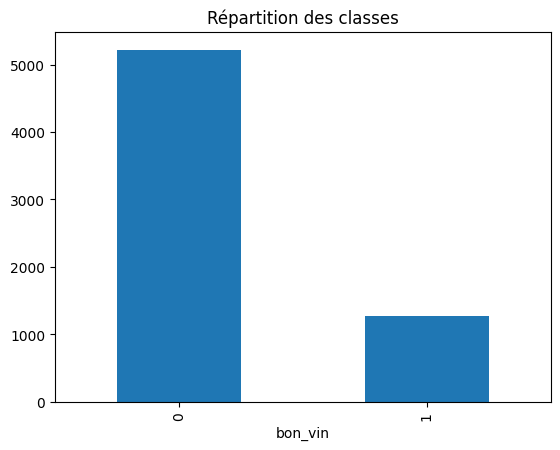

In [7]:
#Distribution des classes
display(df['bon_vin'].value_counts())
display(df['bon_vin'].value_counts(normalize=True))
df['bon_vin'].value_counts().plot(kind='bar')
plt.title("Répartition des classes")
plt.show()

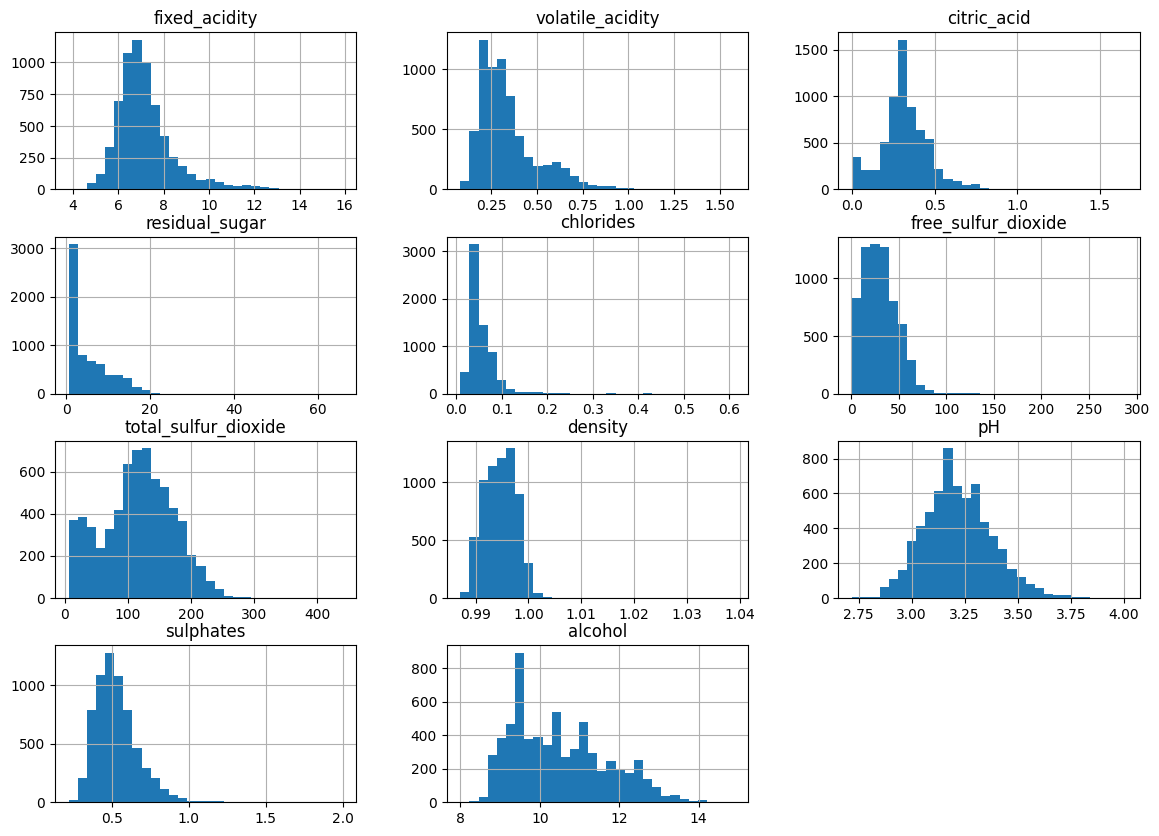

In [8]:
#Distribution des variables
features = df.columns.drop(['quality', 'bon_vin', 'color'])
df[features].hist(bins=30, figsize=(14, 10))
plt.show()

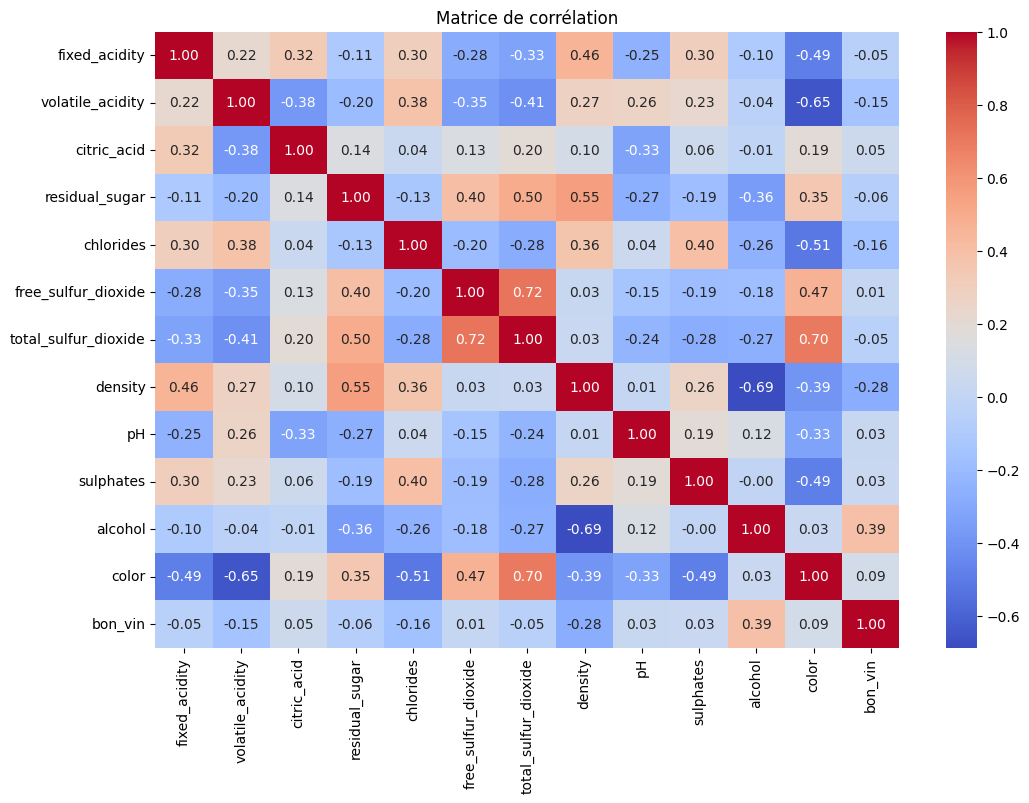

alcohol                 0.390486
color                   0.087479
citric_acid             0.054444
sulphates               0.033971
pH                      0.028149
free_sulfur_dioxide     0.014767
fixed_acidity          -0.049447
total_sulfur_dioxide   -0.051226
residual_sugar         -0.063992
volatile_acidity       -0.151714
chlorides              -0.161781
density                -0.275441
Name: bon_vin, dtype: float64


In [9]:
# Correlation entres variables
corr = df.drop(columns=['quality']).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

# Pour voir ceux qui sont le plus correle avec la variables bon vin (et donc
# sont les plus utiles pour un bon vin)
print(corr['bon_vin'].drop('bon_vin').sort_values(ascending=False))

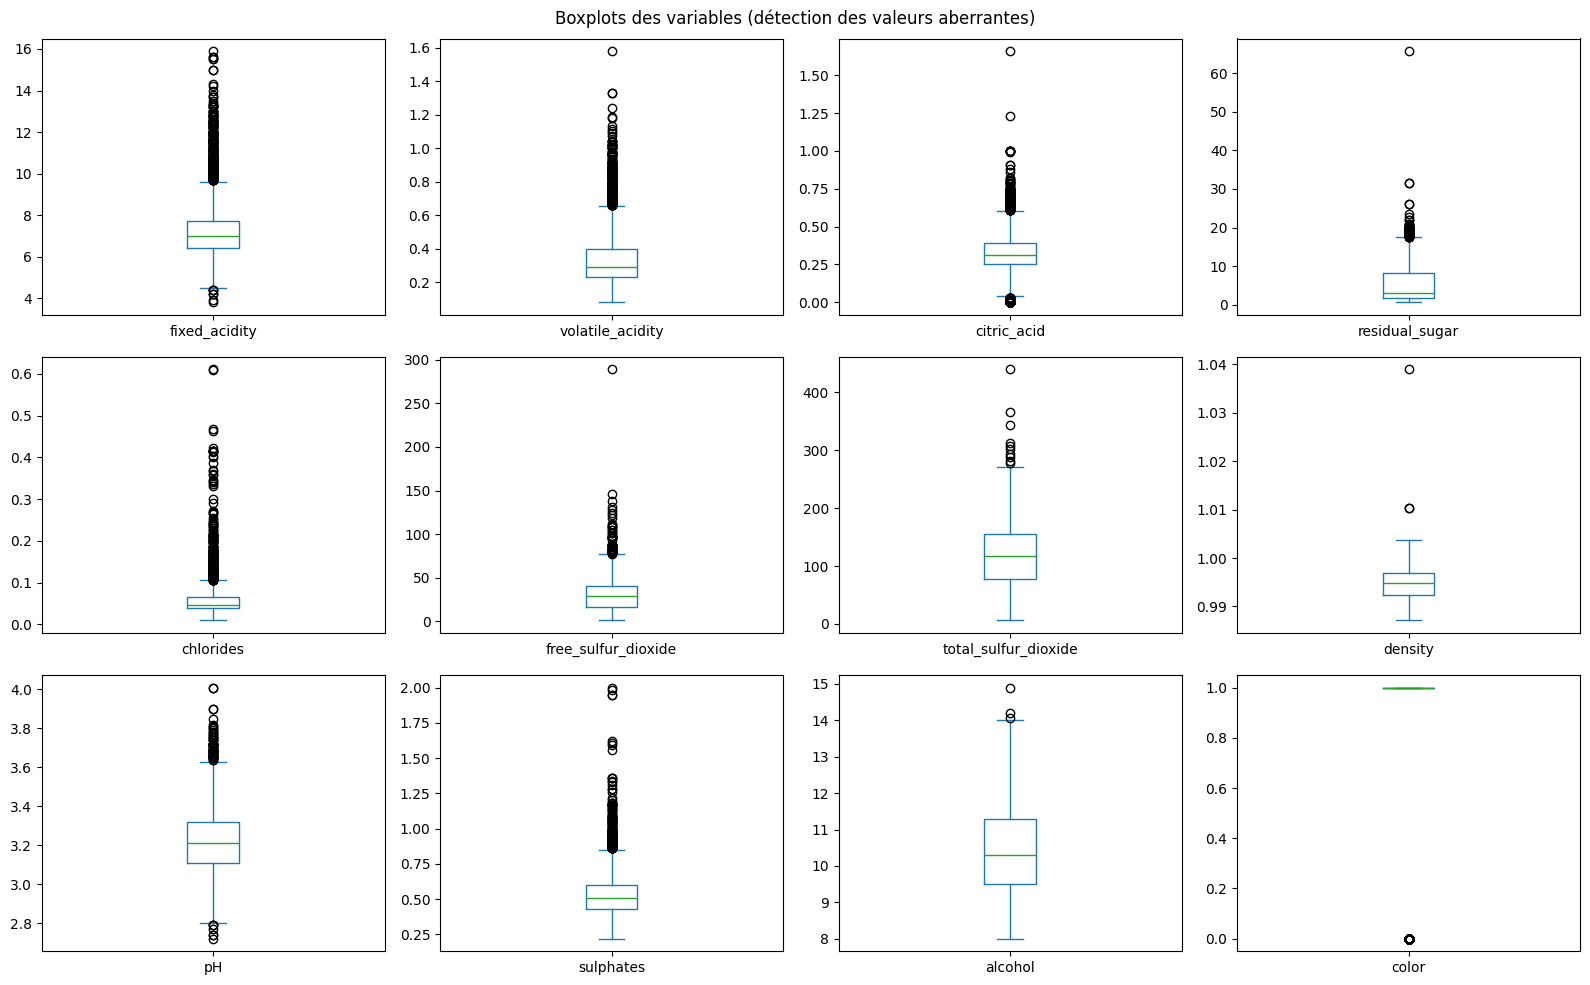

fixed_acidity          :  357 valeurs aberrantes (5.5%)
volatile_acidity       :  377 valeurs aberrantes (5.8%)
citric_acid            :  509 valeurs aberrantes (7.8%)
residual_sugar         :  118 valeurs aberrantes (1.8%)
chlorides              :  286 valeurs aberrantes (4.4%)
free_sulfur_dioxide    :   62 valeurs aberrantes (1.0%)
total_sulfur_dioxide   :   10 valeurs aberrantes (0.2%)
density                :    3 valeurs aberrantes (0.0%)
pH                     :   73 valeurs aberrantes (1.1%)
sulphates              :  191 valeurs aberrantes (2.9%)
alcohol                :    3 valeurs aberrantes (0.0%)
color                  : 1599 valeurs aberrantes (24.6%)


In [10]:
#Détection des valeurs aberrantes
#Boxplots des variables : les points hors des boîtes sont les valeurs aberrantes
features = df.columns.drop(['quality', 'bon_vin'])
df[features].plot(kind='box', subplots=True, layout=(3, 4), figsize=(16, 10), showfliers=True)
plt.suptitle("Boxplots des variables (détection des valeurs aberrantes)")
plt.tight_layout()
plt.show()

for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    nb_aberrantes = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:22s} : {nb_aberrantes:4d} valeurs aberrantes ({nb_aberrantes / len(df) * 100:.1f}%)")

#On garde ces valeurs : ce sont de vrais vins avec des mesures extrêmes, pas des
#erreurs de saisie. Les modèles non linéaires (k-NN, arbre, SVM) les gèrent bien
#et la mise à l'échelle (StandardScaler) limite déjà leur effet sur la régression logistique.

In [11]:
#Séparation du train/test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['quality', 'bon_vin'])
y = df['bon_vin']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)

ss = StandardScaler()
X_train_norm = ss.fit_transform(X_train)
X_test_norm = ss.transform(X_test)

In [12]:
#Sélection de variables : RFE (Recursive Feature Elimination) sur la régression logistique
#On garde l'échelle via un pipeline pour que la sélection soit faite proprement (sur des données normalisées)
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=6)
rfe.fit(X_train_norm, y_train)

selection = pandas.DataFrame({
    'Variable': X.columns,
    'Sélectionnée': rfe.support_,
    'Rang': rfe.ranking_,
}).sort_values('Rang')
display(selection)
print("Variables gardées par la RFE :", list(X.columns[rfe.support_]))

#Les variables éliminées par la RFE sont aussi celles les moins corrélées à bon_vin
#(ex: pH ~ -0.03, fixed_acidity ~ -0.05), et plusieurs variables sont très corrélées entre elles
#(ex: free/total sulfur dioxide, density/residual sugar), donc leur information est redondante.
#Comme la RFE ne montre pas de gain net à réduire, on garde les 12 variables pour les
#modèles, mais cette analyse justifie qu'un sous-ensemble marcherait aussi bien.

,Variable,Sélectionnée,Rang
0,fixed_acidity,True,1
1,volatile_acidity,True,1
3,residual_sugar,True,1
7,density,True,1
8,pH,True,1
10,alcohol,True,1
9,sulphates,False,2
6,total_sulfur_dioxide,False,3
5,free_sulfur_dioxide,False,4
4,chlorides,False,5


Variables gardées par la RFE : ['fixed_acidity', 'volatile_acidity', 'residual_sugar', 'density', 'pH', 'alcohol']


**Pourquoi ces 5 modèles ?**

Le projet demande 5 modèles différents. On prend des modèles linéaires (simples, qui séparent les données avec une droite) et des modèles non linéaires (qui peuvent faire des formes plus compliquées), pour bien comparer les deux familles :

- **Régression logistique (linéaire)** : c'est le modèle le plus simple et le plus facile à comprendre. Chaque coefficient dit si une variable augmente ou diminue la chance d'avoir un bon vin. Normalement, plus l'alcool est haut et plus la densité est basse, plus le vin est bon, donc une droite devrait déjà marcher pas trop mal.
- **k-NN (non linéaire)** : il regarde les vins les plus proches (les plus ressemblants) et vote avec eux. Il n'impose aucune forme à la frontière. Il faut normaliser les données avant (avec StandardScaler), sinon les variables avec de grands chiffres écrasent les autres.
- **Arbre de décision (non linéaire)** : il pose des questions du genre "alcool > 10.5 ?" les unes après les autres. C'est très facile à lire et à expliquer. Mais il apprend souvent par cœur le jeu d'entraînement (il fait du sur-apprentissage), donc on limite sa taille avec ses hyperparamètres.
- **Naive Bayes (non linéaire)** : très rapide et simple. Il suppose que les variables sont indépendantes entre elles, ce qui est faux ici (par exemple free sulfur dioxide et total sulfur dioxide sont très corrélées). Du coup on s'attend à ce qu'il soit le moins bon, et ça nous sert d'exemple pour comprendre l'importance de cette hypothèse.
- **SVM avec noyau RBF (non linéaire)** : il peut tracer des frontières très compliquées. C'est d'ailleurs le meilleur modèle dans l'article d'origine du dataset (Cortez et al., 2009). Il faut aussi normaliser les données avant.

Comme il y a beaucoup moins de bons vins que de mauvais (environ 20% contre 80%), on a fait 3 choses :
1. garder les mêmes proportions dans le train et le test (stratify) ;
2. mettre class_weight='balanced' dans les modèles qui le permettent, pour que les erreurs sur les bons vins comptent plus cher ;
3. optimiser avec le F1-score et non l'accuracy, car un modèle qui dirait toujours "mauvais vin" aurait 80% d'accuracy mais 0% de bons vins trouvés.

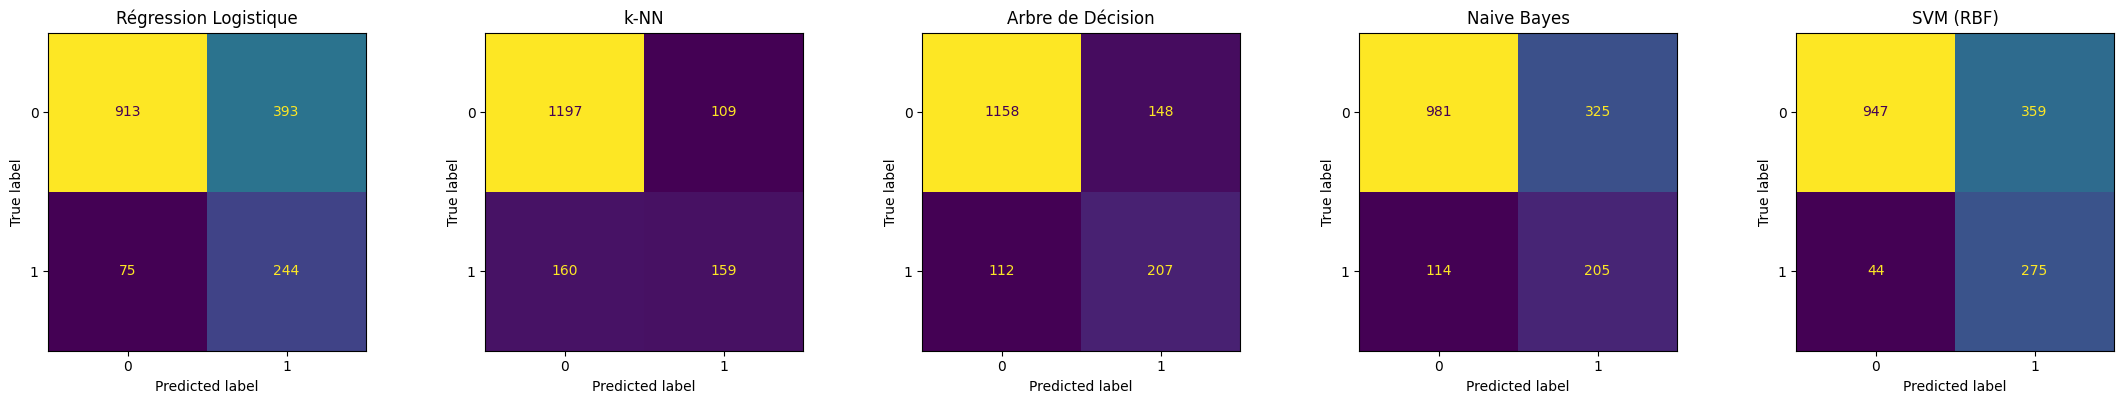

============================== Régression Logistique ==============================
              precision    recall  f1-score   support

 mauvais vin       0.92      0.70      0.80      1306
     bon vin       0.38      0.76      0.51       319

    accuracy                           0.71      1625
   macro avg       0.65      0.73      0.65      1625
weighted avg       0.82      0.71      0.74      1625

============================== k-NN ==============================
              precision    recall  f1-score   support

 mauvais vin       0.88      0.92      0.90      1306
     bon vin       0.59      0.50      0.54       319

    accuracy                           0.83      1625
   macro avg       0.74      0.71      0.72      1625
weighted avg       0.83      0.83      0.83      1625

============================== Arbre de Décision ==============================
              precision    recall  f1-score   support

 mauvais vin       0.91      0.89      0.90      1306
     b

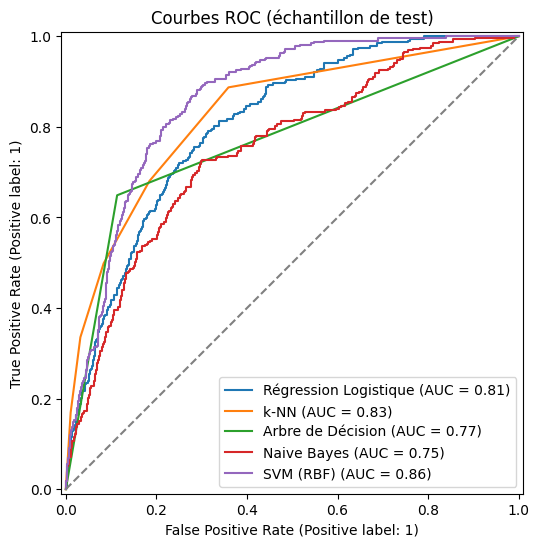

,Accuracy,Précision,Rappel,F1-score,AUC
Régression Logistique,0.712,0.383,0.765,0.510,0.805
k-NN,0.834,0.593,0.498,0.542,0.829
Arbre de Décision,0.840,0.583,0.649,0.614,0.768
Naive Bayes,0.730,0.387,0.643,0.483,0.751
SVM (RBF),0.752,0.434,0.862,0.577,0.860


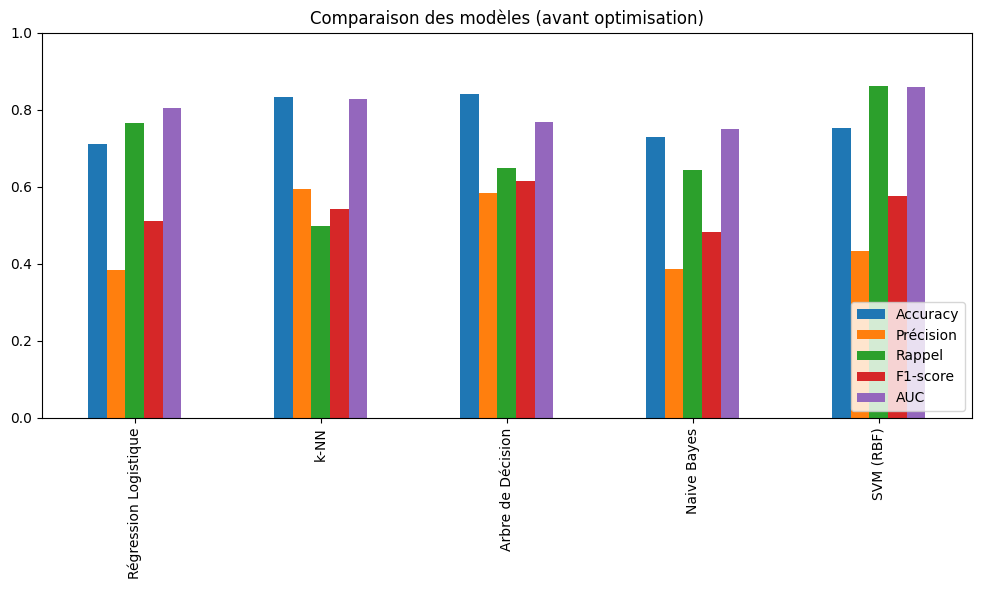

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, roc_auc_score)
from sklearn.model_selection import learning_curve

def score_continu(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X)

modeles = {
    'Régression Logistique': LogisticRegression(max_iter=5000, class_weight='balanced', random_state=1),
    'k-NN':                  KNeighborsClassifier(),
    'Arbre de Décision':     DecisionTreeClassifier(random_state=1),
    'Naive Bayes':           GaussianNB(),
    'SVM (RBF)':             SVC(class_weight='balanced', random_state=1),
}

resultats = {}
fig_cm, axes_cm = plt.subplots(1, 5, figsize=(22, 4))
for ax, (nom, model) in zip(axes_cm, modeles.items()):
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_score = score_continu(model, X_test_norm)
    resultats[nom] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Précision': precision_score(y_test, y_pred),
        'Rappel':    recall_score(y_test, y_pred),
        'F1-score':  f1_score(y_test, y_pred),
        'AUC':       roc_auc_score(y_test, y_score),
    }
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, colorbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

for nom, model in modeles.items():
    print('=' * 30, nom, '=' * 30)
    print(classification_report(y_test, model.predict(X_test_norm),
                                target_names=['mauvais vin', 'bon vin']))

fig_roc, ax_roc = plt.subplots(figsize=(8, 6))
for nom, model in modeles.items():
    RocCurveDisplay.from_estimator(model, X_test_norm, y_test, name=nom, ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], linestyle='--', color='grey')
ax_roc.set_title("Courbes ROC (échantillon de test)")
plt.show()

df_resultats = pandas.DataFrame(resultats).T.round(3)
display(df_resultats)

df_resultats.plot(kind='bar', figsize=(12, 5))
plt.title("Comparaison des modèles (avant optimisation)")
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()


**Optimisation des hyperparamètres**


In [14]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
from scipy.stats import uniform

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

grilles = {
    'Régression Logistique': (GridSearchCV, {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['liblinear', 'lbfgs', 'saga'],
        'class_weight': [None, 'balanced'],
    }),
    'k-NN': (GridSearchCV, {
        'n_neighbors': list(range(1, 31, 2)),
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan'],
    }),
    'Arbre de Décision': (GridSearchCV, {
        'max_depth': [3, 5, 7, 10, 15, None],
        'min_samples_split': [2, 10, 20],
        'min_samples_leaf': [1, 5, 10],
        'criterion': ['gini', 'entropy'],
        'class_weight': [None, 'balanced'],
    }),
    'Naive Bayes': (GridSearchCV, {
        'var_smoothing': [1e-10, 1e-9, 1e-8, 1e-7, 1e-6],
    }),
    'SVM (RBF)': (RandomizedSearchCV, {
        'C': uniform(0.1, 100),
        'gamma': uniform(0.001, 1),
        'kernel': ['rbf'],
        'class_weight': [None, 'balanced'],
    }),
}

meilleurs_modeles = {}
for nom, (cls, grille) in grilles.items():
    if cls is RandomizedSearchCV:
        search = cls(modeles[nom], param_distributions=dict(grille), scoring='f1',
                     cv=cv, n_jobs=-1, refit=True, random_state=1, n_iter=60)
    else:
        search = cls(modeles[nom], param_grid=grille, scoring='f1',
                     cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train_norm, y_train)
    meilleurs_modeles[nom] = search.best_estimator_
    scores = cross_val_score(search.best_estimator_, X_train_norm, y_train,
                             cv=cv, scoring='f1', n_jobs=-1)
    print(f"{nom} : meilleur(paramètre) {search.best_params_}")
    print(f"  F1 (CV 5-fold) = {scores.mean():.3f} +/- {scores.std():.3f}")


Régression Logistique : meilleur(paramètre) {'C': 0.01, 'class_weight': 'balanced', 'solver': 'lbfgs'}
  F1 (CV 5-fold) = 0.533 +/- 0.007
k-NN : meilleur(paramètre) {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
  F1 (CV 5-fold) = 0.638 +/- 0.027
Arbre de Décision : meilleur(paramètre) {'class_weight': None, 'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2}
  F1 (CV 5-fold) = 0.572 +/- 0.015
Naive Bayes : meilleur(paramètre) {'var_smoothing': 1e-10}
  F1 (CV 5-fold) = 0.490 +/- 0.014
SVM (RBF) : meilleur(paramètre) {'C': 5.436254511708038, 'class_weight': 'balanced', 'gamma': 0.6149383177960557, 'kernel': 'rbf'}
  F1 (CV 5-fold) = 0.630 +/- 0.022


,Accuracy,Précision,Rappel,F1-score,AUC,F1 train
Régression Logistique,0.714,0.386,0.771,0.514,0.801,0.535
k-NN,0.869,0.678,0.633,0.655,0.882,1.000
Arbre de Décision,0.839,0.585,0.618,0.601,0.767,0.974
Naive Bayes,0.730,0.387,0.643,0.483,0.751,0.493
SVM (RBF),0.852,0.610,0.677,0.642,0.868,0.952


<Figure size 800x500 with 0 Axes>

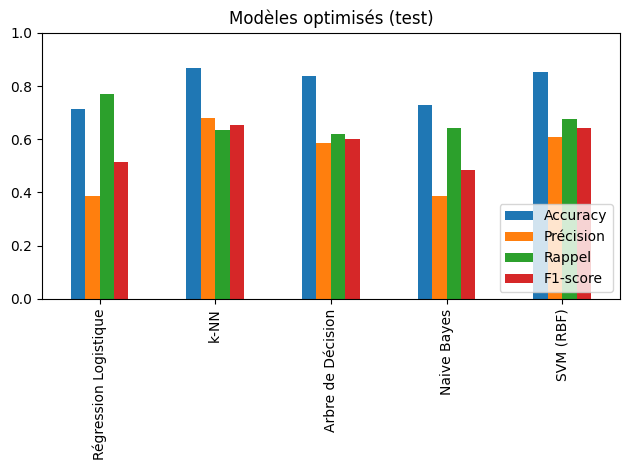

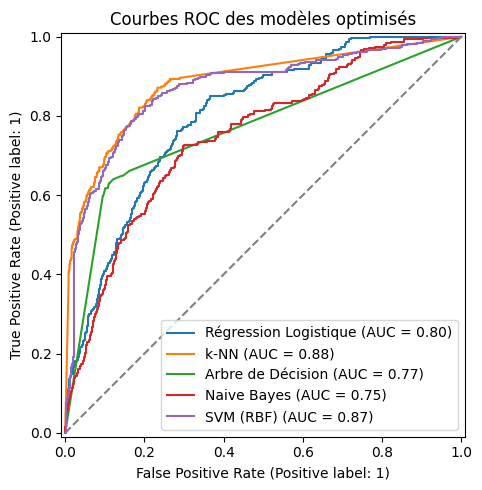

Meilleur modèle : k-NN


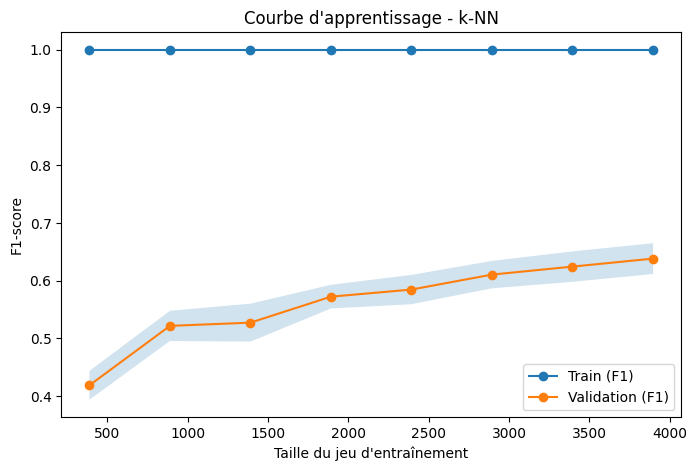

In [16]:
resultats_opti = {}
for nom, model in meilleurs_modeles.items():
    y_pred = model.predict(X_test_norm)
    y_score = score_continu(model, X_test_norm)
    resultats_opti[nom] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Précision': precision_score(y_test, y_pred),
        'Rappel':    recall_score(y_test, y_pred),
        'F1-score':  f1_score(y_test, y_pred),
        'AUC':       roc_auc_score(y_test, y_score),
        'F1 train':  f1_score(y_train, model.predict(X_train_norm)),
    }

df_opti = pandas.DataFrame(resultats_opti).T.round(3)
display(df_opti)

fig_opti = plt.figure(figsize=(8, 5))
df_opti[['Accuracy', 'Précision', 'Rappel', 'F1-score']].plot(kind='bar')
plt.title("Modèles optimisés (test)")
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

fig_roc = plt.figure(figsize=(8, 5))
ax_roc = fig_roc.add_subplot(111)

for nom, model in meilleurs_modeles.items():
    RocCurveDisplay.from_estimator(model, X_test_norm, y_test, name=nom, ax=ax_roc)

ax_roc.plot([0, 1], [0, 1], linestyle='--', color='grey')
ax_roc.set_title("Courbes ROC des modèles optimisés")
plt.tight_layout()
plt.show()

meilleur_nom = df_opti['F1-score'].idxmax()
print("Meilleur modèle :", meilleur_nom)

train_sizes, train_scores, val_scores = learning_curve(
    meilleurs_modeles[meilleur_nom], X_train_norm, y_train,
    cv=cv, scoring='f1', train_sizes=numpy.linspace(0.1, 1.0, 8), n_jobs=-1)
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train (F1)')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation (F1)')
plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel("Taille du jeu d'entraînement")
plt.ylabel('F1-score')
plt.title(f"Courbe d'apprentissage - {meilleur_nom}")
plt.legend()
plt.show()


**Que disent les résultats ?**

| Modèle | F1 (test) | AUC | Ce qu'on en dit |
|---|---|---|---|
| k-NN | 0.655 | 0.882 | le meilleur |
| SVM (RBF) | 0.642 | 0.868 | très proche du k-NN |
| Arbre de décision | 0.601 | 0.767 | apprend par cœur |
| Régression logistique | 0.514 | 0.801 | trop simple |
| Naive Bayes | 0.483 | 0.751 | le moins bon |

- **k-NN gagne (F1 = 0.655, AUC = 0.882)** : la frontière entre bon et mauvais vin n'est pas une droite, et le k-NN suit les formes locales des données. Attention, son F1 sur le train est de 1.0 : il apprend aussi par cœur, mais il reste le meilleur sur les données qu'il n'a jamais vues, et la validation croisée (F1 = 0.638 +/- 0.027) montre qu'il est stable.
- **SVM (RBF)** est juste derrière, avec par contre le meilleur rappel sur les bons vins : c'est lui qu'on choisit si on ne veut surtout pas rater un bon vin, même si du coup il se trompe plus souvent en disant que c'est un bon vin.
- **Arbre de décision** : F1 de 0.974 sur le train mais seulement 0.601 sur le test. Cet énorme écart montre qu'il a appris par cœur et qu'il est en sur-apprentissage, même après avoir limité sa taille.
- **Régression logistique** : son F1 est presque pareil sur le train (0.535) et le test (0.514). Elle est donc stable, mais trop simple : la vraie frontière n'est pas une droite, donc elle fait beaucoup d'erreurs. C'est un bon contrôle pour comparer avec les modèles plus forts.
- **Naive Bayes** est le moins bon, comme on l'avait prévu, à cause de son hypothèse d'indépendance falsifiée par les variables corrélées.

**Compromis biais/variance** : la régression logistique a un gros biais (trop simple) mais presque pas de variance. L'arbre et le k-NN ont peu de biais mais beaucoup de variance. Le meilleur équilibre ici est le k-NN, qui garde le meilleur score de test. La courbe d'apprentissage montre aussi que le F1 sur la validation continue de monter quand on lui donne plus de données : avec encore plus de vins, ses résultats seraient encore meilleurs.

**Conclusion sur les hyperparamètres** : On remarque que le F1 score de certains modèles ont grimpé avec l'utilisation de *5 folds*, tel que le KNN et la régression linéaire, tandis que l'arbre de décision et le Naive Bayes demeurent inchangé, voire diminuent. Ceci peut s'expliquer par le calcul du F1 score, qui dépend du Recall et de la Précision. Si l'un de ces deux métriques baisse, le F1 score baisse aussi, et inversement. En somme, l'utilisation de *folds* est dans la plupart des cas bénéfiques pour les modèles, car les bons vins marquent une place plus importante dans des petits échantillons. Les méthodes de GridSearch et de RandomaizedSearch ont permis de trouver les paramètres adéquats, bien que le RandomSearch n'a d'efficacités si et seulement l'intervalle encadre la meilleure valeur. Dans le cas du SVM, on distingue que l'intervalle était de 0.1 à 100, et que le meilleur paramètre a été déterminé à 5.43, nous faisant perdre en efficacité et en précision. 